# Exploratory Data Analysis (EDA) pada Dataset *Student Performance Factors*

**Tugas Sub-CLO-12-1-1 — Visualisasi Data**

| | |
|---|---|
| **Nama** | Faisal Surya Saputra |
| **NIM** | 103012330152 |


## 0. Langkah-Langkah Pengerjaan

Sebelum mulai menulis kode, saya menyusun dulu alur kerja supaya eksplorasi data berjalan runtut dan sesuai ketentuan tugas:

1. **Menentukan dataset dan tujuan analisis.** Saya memilih dataset *Student Performance Factors* dari Kaggle, lalu merumuskan pertanyaan yang ingin dijawab.
2. **Menyiapkan lingkungan kerja.** Mengimpor pustaka (pandas, numpy, matplotlib, seaborn, scikit-learn) dan memuat dataset.
3. **Data profiling dan validasi.** Melihat struktur data, statistik deskriptif, *missing value*, duplikat, serta indikasi awal outlier/anomali.
4. **Data cleaning ringan.** Menangani masalah yang ditemukan pada langkah 3 dan mendokumentasikannya.
5. **Univariate visualization.** Melihat distribusi tiap variabel numerik (histogram, density, boxplot) dan variabel kategorikal (bar chart).
6. **Bivariate visualization.** Melihat hubungan beberapa variabel dengan variabel fokus, yaitu `Exam_Score`.
7. **Multivariate visualization.** Correlation heatmap dan pair plot untuk melihat pola antar banyak variabel sekaligus.
8. **Dimensionality reduction.** Menerapkan PCA, membaca *explained variance* dan kontribusi variabel, serta menambahkan dendrogram sebagai bonus.
9. **Insight, kesimpulan, dan rekomendasi.**
10. **Lembar deklarasi penggunaan AI** dan **daftar pustaka**.

Setiap tahap saya awali dengan penjelasan tujuan, lalu kode, dan saya akhiri dengan interpretasi hasilnya.

## 1. Deskripsi Dataset

**Sumber data:** Kaggle — *Student Performance Factors* oleh Lai Nguyen
🔗 https://www.kaggle.com/datasets/lainguyn123/student-performance-factors

**Konteks data.** Dataset ini berisi data siswa beserta berbagai faktor yang diduga memengaruhi hasil ujian, mulai dari kebiasaan belajar (jam belajar, kehadiran, jam tidur, les tambahan), latar belakang keluarga (keterlibatan orang tua, pendidikan orang tua, pendapatan keluarga), sampai kondisi lingkungan belajar (kualitas guru, tipe sekolah, akses internet dan sumber belajar, pengaruh teman, jarak rumah ke sekolah). Variabel hasil/target yang saya fokuskan adalah **`Exam_Score`** (nilai ujian akhir).

**Mengapa dataset ini saya pilih.**
- Merupakan dataset nyata dari platform data terbuka (Kaggle) dan bukan data buatan sendiri.
- Memenuhi syarat ukuran: lebih dari 500 baris dan lebih dari 8 kolom, dengan campuran variabel numerik dan kategorikal.
- Bukan dataset klasik tutorial dasar (seperti Titanic atau Iris) dan tidak dipakai sebagai contoh di kelas.
- Topiknya dekat dengan dunia pendidikan, sehingga insight-nya mudah dikaitkan dengan konteks kebijakan.

**Tujuan analisis.** Saya ingin menjawab pertanyaan-pertanyaan berikut:
1. Bagaimana kualitas data (missing value, duplikat, anomali) dan apa yang perlu dibersihkan?
2. Bagaimana sebaran nilai ujian siswa dan variabel-variabel pendukungnya?
3. Faktor apa yang paling kuat berhubungan dengan `Exam_Score`?
4. Apakah faktor kategorikal seperti keterlibatan orang tua, akses sumber belajar, dan motivasi membedakan nilai ujian?
5. Apakah struktur data dapat diringkas ke dimensi yang lebih kecil melalui PCA?

## 2. Persiapan Lingkungan dan Pemuatan Data

**Tujuan:** menyiapkan pustaka yang dibutuhkan dan memuat dataset langsung dari Kaggle memakai `kagglehub`.

**Langkah:**
1. Instal `kagglehub` (hanya perlu sekali, lewati bila sudah terpasang).
2. Impor seluruh pustaka dan atur tema visualisasi agar konsisten.
3. Muat dataset. Sebagai cadangan, bila `kagglehub` gagal (misalnya tidak ada koneksi), kode akan membaca file `StudentPerformanceFactors.csv` dari folder yang sama dengan notebook.

In [1]:
# Instalasi dependensi (jalankan sekali bila belum terpasang)
%pip install -q "kagglehub[pandas-datasets]"

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (dibutuhkan untuk plot 3D)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
print("Pustaka berhasil diimpor.")

Pustaka berhasil diimpor.


In [3]:
# Memuat dataset dari Kaggle (dengan cadangan membaca CSV lokal)
FILE_PATH = "StudentPerformanceFactors.csv"

try:
    import kagglehub
    from kagglehub import KaggleDatasetAdapter

    df = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "lainguyn123/student-performance-factors",
        FILE_PATH,
    )
    print("Dataset dimuat melalui kagglehub.")
except Exception as e:
    print(f"kagglehub gagal ({type(e).__name__}); membaca file CSV lokal.")
    df = pd.read_csv(FILE_PATH)

print("\n5 data pertama:")
df.head()

Using Colab cache for faster access to the 'student-performance-factors' dataset.
Dataset dimuat melalui kagglehub.

5 data pertama:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


**Catatan hasil.** Dataset berhasil dimuat dan 5 baris pertama sudah tampil. Dari sini terlihat kolom-kolom bertipe angka (misalnya `Hours_Studied`, `Attendance`, `Exam_Score`) dan kolom bertipe teks/kategori (misalnya `Parental_Involvement`, `School_Type`, `Gender`). Langkah berikutnya adalah memeriksa struktur dan kualitas data secara lebih rinci.

## 3. Data Profiling dan Validasi Data

**Tujuan:** memahami struktur dataset dan memastikan datanya layak dianalisis sebelum divisualisasikan.

**Langkah:**
1. Melihat jumlah baris, kolom, dan tipe data tiap kolom.
2. Menghitung statistik deskriptif variabel numerik dan kategorikal.
3. Memeriksa *missing value* dan data duplikat.
4. Mengidentifikasi potensi outlier (aturan IQR) dan anomali nilai (nilai di luar rentang yang masuk akal).

### 3.1 Struktur Dataset

In [4]:
print(f"Jumlah baris  : {df.shape[0]:,}")
print(f"Jumlah kolom  : {df.shape[1]}")
print()
df.info()

Jumlah baris  : 6,607
Jumlah kolom  : 20

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_I

In [5]:
# Pemisahan kolom numerik dan kategorikal
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print(f"Variabel numerik ({len(num_cols)})    : {num_cols}")
print(f"Variabel kategorikal ({len(cat_cols)}): {cat_cols}")

Variabel numerik (7)    : ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']
Variabel kategorikal (13): ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


**Interpretasi.** Dataset memiliki lebih dari 6.000 observasi dan 20 variabel, sehingga memenuhi syarat minimal tugas (≥ 500 baris dan ≥ 8 kolom). Variabel terdiri dari 7 kolom numerik (jam belajar, kehadiran, jam tidur, nilai sebelumnya, jumlah sesi les, aktivitas fisik, dan nilai ujian) dan 13 kolom kategorikal. Hasil `info()` juga memberi petunjuk awal bahwa ada beberapa kolom kategorikal dengan jumlah data non-null lebih sedikit dari total baris, yang berarti ada *missing value*. Hal ini saya konfirmasi pada bagian 3.3.

### 3.2 Statistik Deskriptif

In [6]:
# Statistik deskriptif variabel numerik (ditambah median)
desc = df[num_cols].describe().T
desc["median"] = df[num_cols].median()
desc = desc[["count", "mean", "median", "std", "min", "25%", "75%", "max"]]
desc

,count,mean,median,std,min,25%,75%,max
Hours_Studied,"6,607.000",19.975,20.000,5.991,1.000,16.000,24.000,44.000
Attendance,"6,607.000",79.977,80.000,11.547,60.000,70.000,90.000,100.000
Sleep_Hours,"6,607.000",7.029,7.000,1.468,4.000,6.000,8.000,10.000
Previous_Scores,"6,607.000",75.071,75.000,14.400,50.000,63.000,88.000,100.000
Tutoring_Sessions,"6,607.000",1.494,1.000,1.231,0.000,1.000,2.000,8.000
Physical_Activity,"6,607.000",2.968,3.000,1.031,0.000,2.000,4.000,6.000
Exam_Score,"6,607.000",67.236,67.000,3.890,55.000,65.000,69.000,101.000


In [7]:
# Statistik deskriptif variabel kategorikal
df[cat_cols].describe().T

,count,unique,top,freq
Parental_Involvement,6607,3,Medium,3362
Access_to_Resources,6607,3,Medium,3319
Extracurricular_Activities,6607,2,Yes,3938
Motivation_Level,6607,3,Medium,3351
Internet_Access,6607,2,Yes,6108
Family_Income,6607,3,Low,2672
Teacher_Quality,6529,3,Medium,3925
School_Type,6607,2,Public,4598
Peer_Influence,6607,3,Positive,2638
Learning_Disabilities,6607,2,No,5912


In [8]:
# Frekuensi nilai unik tiap variabel kategorikal
for c in cat_cols:
    print(f"--- {c} ---")
    print(df[c].value_counts(dropna=False).to_string())
    print()

--- Parental_Involvement ---
Parental_Involvement
Medium    3362
High      1908
Low       1337

--- Access_to_Resources ---
Access_to_Resources
Medium    3319
High      1975
Low       1313

--- Extracurricular_Activities ---
Extracurricular_Activities
Yes    3938
No     2669

--- Motivation_Level ---
Motivation_Level
Medium    3351
Low       1937
High      1319

--- Internet_Access ---
Internet_Access
Yes    6108
No      499

--- Family_Income ---
Family_Income
Low       2672
Medium    2666
High      1269

--- Teacher_Quality ---
Teacher_Quality
Medium    3925
High      1947
Low        657
NaN         78

--- School_Type ---
School_Type
Public     4598
Private    2009

--- Peer_Influence ---
Peer_Influence
Positive    2638
Neutral     2592
Negative    1377

--- Learning_Disabilities ---
Learning_Disabilities
No     5912
Yes     695

--- Parental_Education_Level ---
Parental_Education_Level
High School     3223
College         1989
Postgraduate    1305
NaN               90

--- Distance

**Interpretasi.**
- Nilai rata-rata dan median pada sebagian besar variabel numerik berdekatan, yang menandakan distribusi yang relatif simetris. Contohnya `Hours_Studied` rata-rata sekitar 20 jam per minggu dan `Attendance` sekitar 80%.
- `Exam_Score` memiliki rata-rata sekitar 67 dengan simpangan baku yang kecil (sekitar 4 poin), artinya nilai siswa cenderung mengumpul di rentang yang sempit. Nilai maksimum yang lebih tinggi dari 100 perlu dicurigai sebagai anomali (nilai ujian tidak mungkin melebihi 100). Ini saya periksa pada bagian 3.4.
- Pada variabel kategorikal, beberapa kategori mendominasi, misalnya `School_Type` lebih banyak *Public* dan `Gender` lebih banyak *Male*. Ketidakseimbangan ini perlu diingat saat membandingkan kelompok.
- Rentang nilai kategori (Low/Medium/High, Yes/No, dan sebagainya) tampak konsisten, tidak ada salah ketik atau variasi penulisan pada daftar nilai unik di atas.

### 3.3 Missing Value dan Data Duplikat

In [9]:
missing = df.isna().sum().to_frame("jumlah_missing")
missing["persen_missing"] = (missing["jumlah_missing"] / len(df) * 100).round(2)
missing = missing[missing["jumlah_missing"] > 0].sort_values("jumlah_missing", ascending=False)

print("Kolom yang memiliki missing value:")
display(missing)
print(f"\nJumlah baris duplikat: {df.duplicated().sum()}")

Kolom yang memiliki missing value:


,jumlah_missing,persen_missing
Parental_Education_Level,90,1.360
Teacher_Quality,78,1.180
Distance_from_Home,67,1.010



Jumlah baris duplikat: 0


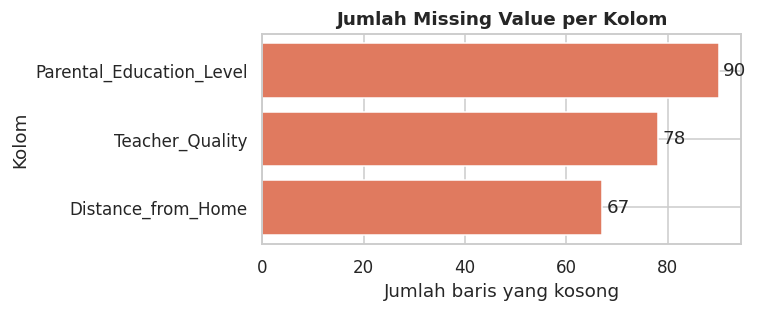

In [10]:
# Visualisasi missing value
miss_all = df.isna().sum()
miss_all = miss_all[miss_all > 0].sort_values()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(miss_all.index, miss_all.values, color="#e07a5f")
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Jumlah Missing Value per Kolom")
ax.set_xlabel("Jumlah baris yang kosong")
ax.set_ylabel("Kolom")
plt.tight_layout()
plt.show()

**Interpretasi.** Missing value hanya ditemukan pada tiga kolom kategorikal, yaitu `Teacher_Quality`, `Parental_Education_Level`, dan `Distance_from_Home`, dengan proporsi sangat kecil (di bawah 2% dari seluruh baris). Tidak ditemukan baris duplikat. Karena proporsinya kecil dan kolomnya kategorikal, penanganan sederhana (imputasi modus) sudah memadai dan tidak akan mengubah pola data secara berarti.

### 3.4 Identifikasi Awal Outlier dan Anomali

In [11]:
# Deteksi outlier dengan aturan IQR (Q1 - 1.5*IQR dan Q3 + 1.5*IQR)
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < low) | (df[c] > high)).sum()
    rows.append({"variabel": c, "batas_bawah": low, "batas_atas": high,
                 "jumlah_outlier": n_out, "persen_outlier": round(n_out / len(df) * 100, 2)})

outlier_tbl = pd.DataFrame(rows).set_index("variabel")
outlier_tbl

,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
variabel,,,,
Hours_Studied,4.000,36.000,43,0.650
Attendance,40.000,120.000,0,0.000
Sleep_Hours,3.000,11.000,0,0.000
Previous_Scores,25.500,125.500,0,0.000
Tutoring_Sessions,-0.500,3.500,430,6.510
Physical_Activity,-1.000,7.000,0,0.000
Exam_Score,59.000,75.000,104,1.570


In [12]:
# Pemeriksaan anomali berdasarkan logika domain
print("Exam_Score > 100 :", (df["Exam_Score"] > 100).sum(), "baris")
print("Attendance > 100 :", (df["Attendance"] > 100).sum(), "baris")
print("Previous_Scores > 100 :", (df["Previous_Scores"] > 100).sum(), "baris")
print("Nilai negatif pada variabel numerik :", int((df[num_cols] < 0).sum().sum()))
print()
df[df["Exam_Score"] > 100]

Exam_Score > 100 : 1 baris
Attendance > 100 : 0 baris
Previous_Scores > 100 : 0 baris
Nilai negatif pada variabel numerik : 0



,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


**Interpretasi.**
- Outlier menurut aturan IQR paling banyak muncul pada `Tutoring_Sessions` (distribusinya miring ke kanan dengan sedikit siswa yang ikut banyak sesi), serta ditemukan pada `Hours_Studied` dan `Exam_Score` dalam jumlah kecil. Outlier ini masih masuk akal secara substansi (siswa yang sangat rajin atau sangat berprestasi), sehingga **tidak saya hapus**.
- Satu temuan yang tidak masuk akal adalah nilai `Exam_Score` yang melebihi 100. Ini merupakan anomali karena nilai ujian maksimal adalah 100, sehingga perlu dikoreksi pada tahap *cleaning*.
- Tidak ditemukan nilai negatif maupun kehadiran/nilai sebelumnya di atas 100.

## 4. Data Cleaning Ringan

**Tujuan:** memperbaiki masalah yang ditemukan saat profiling agar eksplorasi berikutnya valid, dengan perubahan seminimal mungkin.

**Keputusan yang saya ambil:**
1. **Merapikan format teks** pada kolom kategorikal (menghapus spasi di awal/akhir) sebagai langkah pencegahan.
2. **Menghapus baris duplikat** (hasil pemeriksaan: tidak ada, tetapi tetap dijalankan agar notebook tetap benar bila data berubah).
3. **Mengisi missing value dengan modus** pada kolom kategorikal. Alasannya: jumlahnya sangat kecil sehingga menghapus baris akan membuang informasi, dan modus adalah pilihan paling sederhana untuk data kategorikal.
4. **Membatasi (*clip*) `Exam_Score` maksimal 100**, karena nilai di atas 100 adalah anomali. Dipilih *clip* dan bukan menghapus baris agar baris lain pada observasi tersebut tetap terpakai.

Data asli tetap disimpan di `df`, dan data hasil pembersihan disimpan di `df_clean`.

In [13]:
df_clean = df.copy()
n_awal = len(df_clean)

# 1) Rapikan format teks
for c in cat_cols:
    df_clean[c] = df_clean[c].str.strip()

# 2) Hapus duplikat
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Baris duplikat dihapus : {n_awal - len(df_clean)}")

# 3) Isi missing value kategorikal dengan modus
print("\nImputasi missing value (modus):")
for c in df_clean.columns[df_clean.isna().any()]:
    modus = df_clean[c].mode()[0]
    n = df_clean[c].isna().sum()
    df_clean[c] = df_clean[c].fillna(modus)
    print(f"  - {c:<26}: {n:>3} baris diisi dengan '{modus}'")

# 4) Koreksi anomali Exam_Score > 100
n_anom = (df_clean["Exam_Score"] > 100).sum()
df_clean["Exam_Score"] = df_clean["Exam_Score"].clip(upper=100)
print(f"\nAnomali Exam_Score > 100 dikoreksi menjadi 100 : {n_anom} baris")

Baris duplikat dihapus : 0

Imputasi missing value (modus):
  - Teacher_Quality           :  78 baris diisi dengan 'Medium'
  - Parental_Education_Level  :  90 baris diisi dengan 'High School'
  - Distance_from_Home        :  67 baris diisi dengan 'Near'

Anomali Exam_Score > 100 dikoreksi menjadi 100 : 1 baris


In [14]:
# Verifikasi hasil cleaning
print("Sisa missing value :", int(df_clean.isna().sum().sum()))
print("Sisa duplikat      :", int(df_clean.duplicated().sum()))
print("Exam_Score min/max :", df_clean["Exam_Score"].min(), "/", df_clean["Exam_Score"].max())
print("Ukuran data bersih :", df_clean.shape)

Sisa missing value : 0
Sisa duplikat      : 0
Exam_Score min/max : 55 / 100
Ukuran data bersih : (6607, 20)


**Interpretasi.** Setelah cleaning, tidak ada lagi missing value maupun duplikat, dan `Exam_Score` berada dalam rentang yang valid (maksimal 100). Jumlah baris tetap sama dengan data awal sehingga tidak ada informasi yang hilang. Analisis berikutnya memakai `df_clean`.

## 5. Univariate Visualization

**Tujuan:** memahami distribusi tiap variabel secara terpisah, meliputi bentuk sebaran, kemiringan (*skewness*), dan potensi outlier.

**Langkah:**
1. Untuk variabel numerik, saya membuat **histogram + kurva density (KDE)** dan **boxplot** berdampingan pada 5 variabel (`Hours_Studied`, `Attendance`, `Previous_Scores`, `Tutoring_Sessions`, `Exam_Score`).
2. Menghitung nilai *skewness* seluruh variabel numerik.
3. Untuk variabel kategorikal, saya membuat **bar chart** pada 6 variabel.

### 5.1 Variabel Numerik

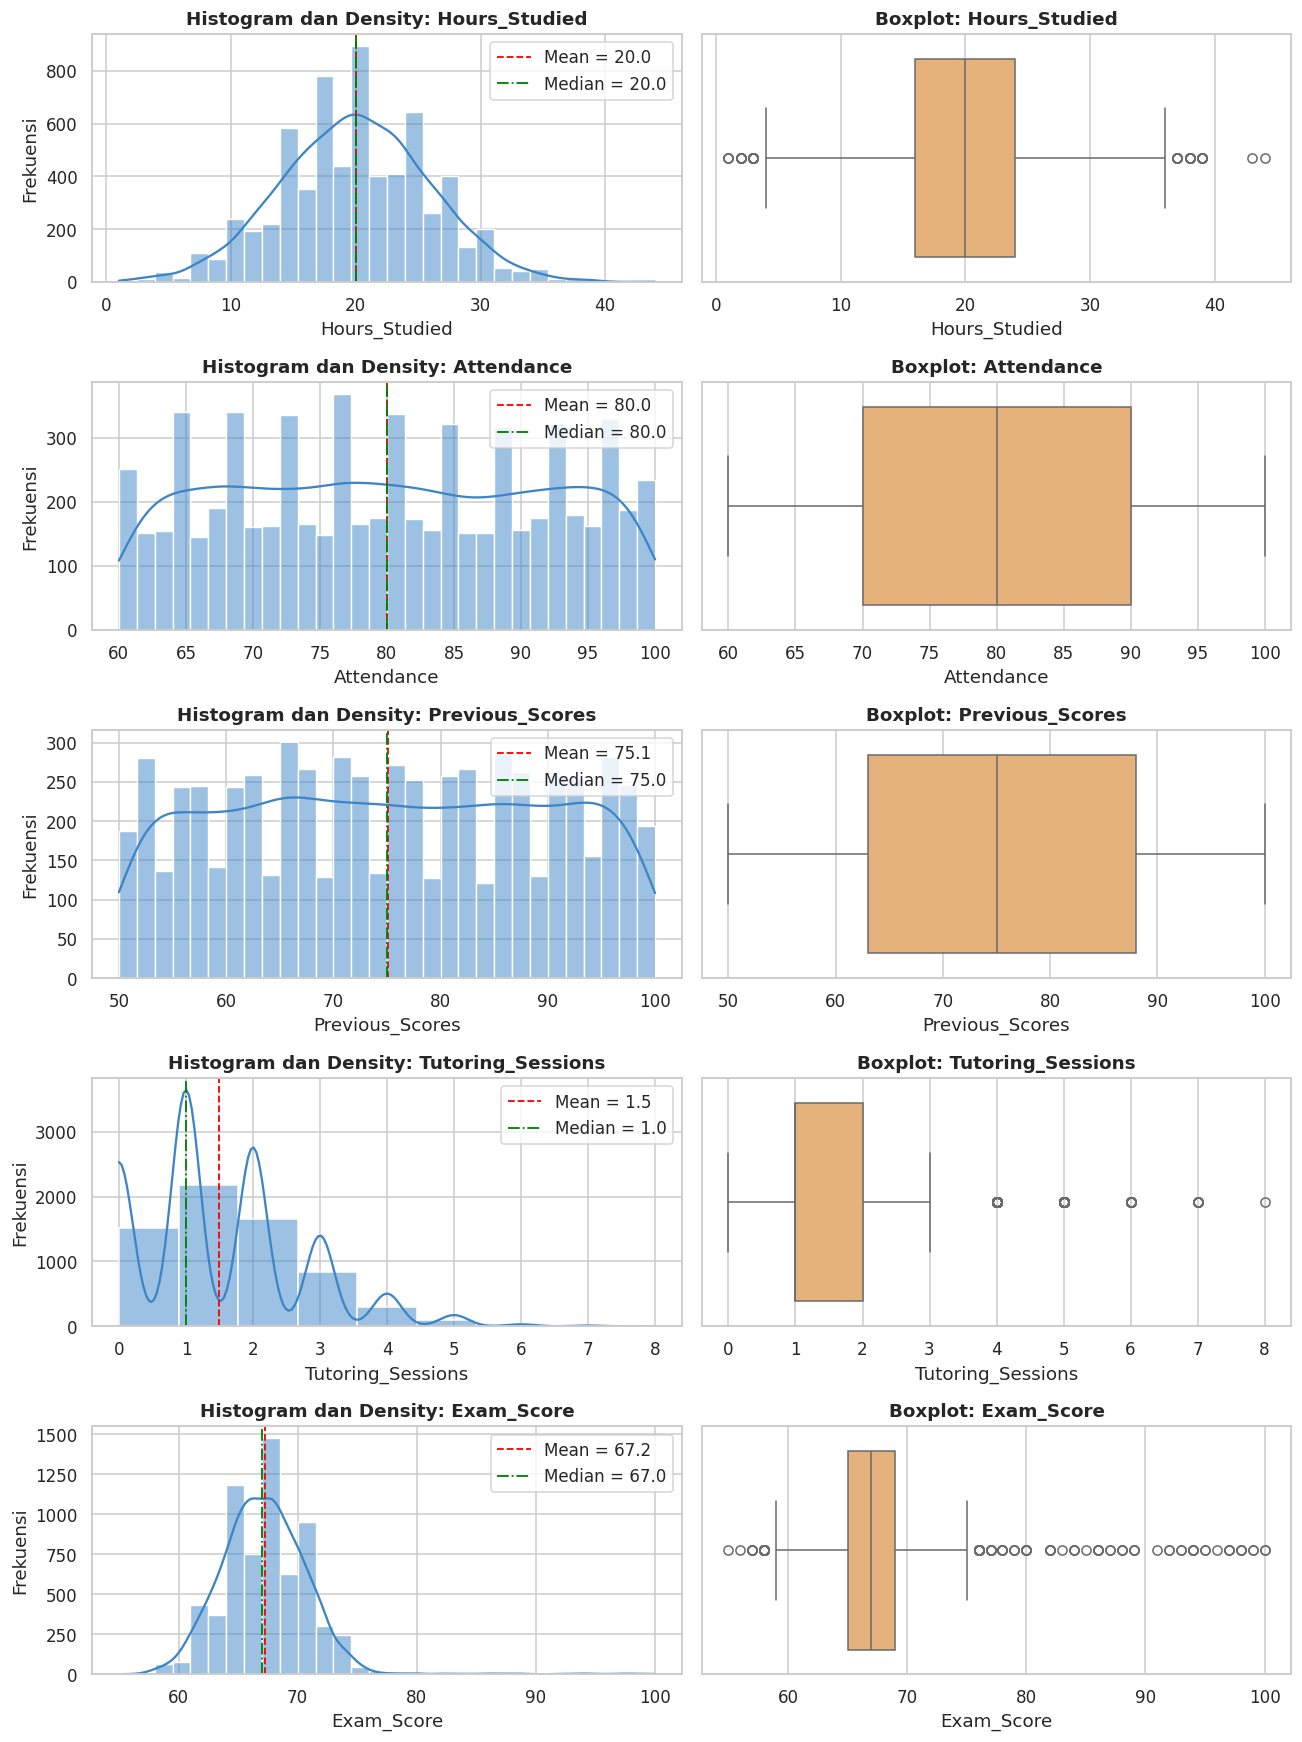

In [15]:
uni_vars = ["Hours_Studied", "Attendance", "Previous_Scores", "Tutoring_Sessions", "Exam_Score"]

fig, axes = plt.subplots(len(uni_vars), 2, figsize=(12, 3.2 * len(uni_vars)))
for i, v in enumerate(uni_vars):
    bins = int(df_clean[v].nunique()) if df_clean[v].nunique() < 15 else 30
    sns.histplot(df_clean[v], bins=bins, kde=True, color="#3d85c6", ax=axes[i, 0])
    axes[i, 0].axvline(df_clean[v].mean(), color="red", ls="--", lw=1.2, label=f"Mean = {df_clean[v].mean():.1f}")
    axes[i, 0].axvline(df_clean[v].median(), color="green", ls="-.", lw=1.2, label=f"Median = {df_clean[v].median():.1f}")
    axes[i, 0].set_title(f"Histogram dan Density: {v}")
    axes[i, 0].set_xlabel(v)
    axes[i, 0].set_ylabel("Frekuensi")
    axes[i, 0].legend()

    sns.boxplot(x=df_clean[v], color="#f6b26b", ax=axes[i, 1])
    axes[i, 1].set_title(f"Boxplot: {v}")
    axes[i, 1].set_xlabel(v)
plt.tight_layout()
plt.show()

In [16]:
# Skewness seluruh variabel numerik
skew_tbl = df_clean[num_cols].skew().sort_values(ascending=False).to_frame("skewness")
skew_tbl["arah"] = np.where(skew_tbl["skewness"] > 0.5, "miring kanan (positif)",
                    np.where(skew_tbl["skewness"] < -0.5, "miring kiri (negatif)", "relatif simetris"))
skew_tbl

,skewness,arah
Exam_Score,1.638,miring kanan (positif)
Tutoring_Sessions,0.816,miring kanan (positif)
Attendance,0.014,relatif simetris
Hours_Studied,0.013,relatif simetris
Previous_Scores,-0.004,relatif simetris
Sleep_Hours,-0.024,relatif simetris
Physical_Activity,-0.031,relatif simetris


**Interpretasi.**
- **`Hours_Studied`**: berbentuk lonceng dan relatif simetris dengan mean dan median hampir sama (sekitar 20 jam). Hanya ada sedikit outlier di sisi ekstrem.
- **`Attendance`**: tersebar cukup merata di rentang sekitar 60–100%, tanpa puncak yang tajam dan tanpa outlier berarti. Skewness mendekati nol.
- **`Previous_Scores`**: bentuknya juga cenderung merata (hampir seragam) di rentang 50–100, dengan mean dan median yang berdekatan serta tanpa outlier.
- **`Tutoring_Sessions`**: bersifat diskrit dan **miring ke kanan**. Sebagian besar siswa hanya mengikuti 0–2 sesi, dan sedikit siswa dengan banyak sesi terdeteksi sebagai outlier. Ini variabel dengan skewness paling jelas.
- **`Exam_Score`**: berbentuk lonceng dengan sedikit ekor ke kanan. Sebagian besar nilai mengumpul di sekitar 65–70, sementara nilai tinggi (di atas 80) tampak sebagai outlier. Sebarannya sempit sehingga selisih antar kelompok nantinya akan terlihat kecil.

### 5.2 Variabel Kategorikal

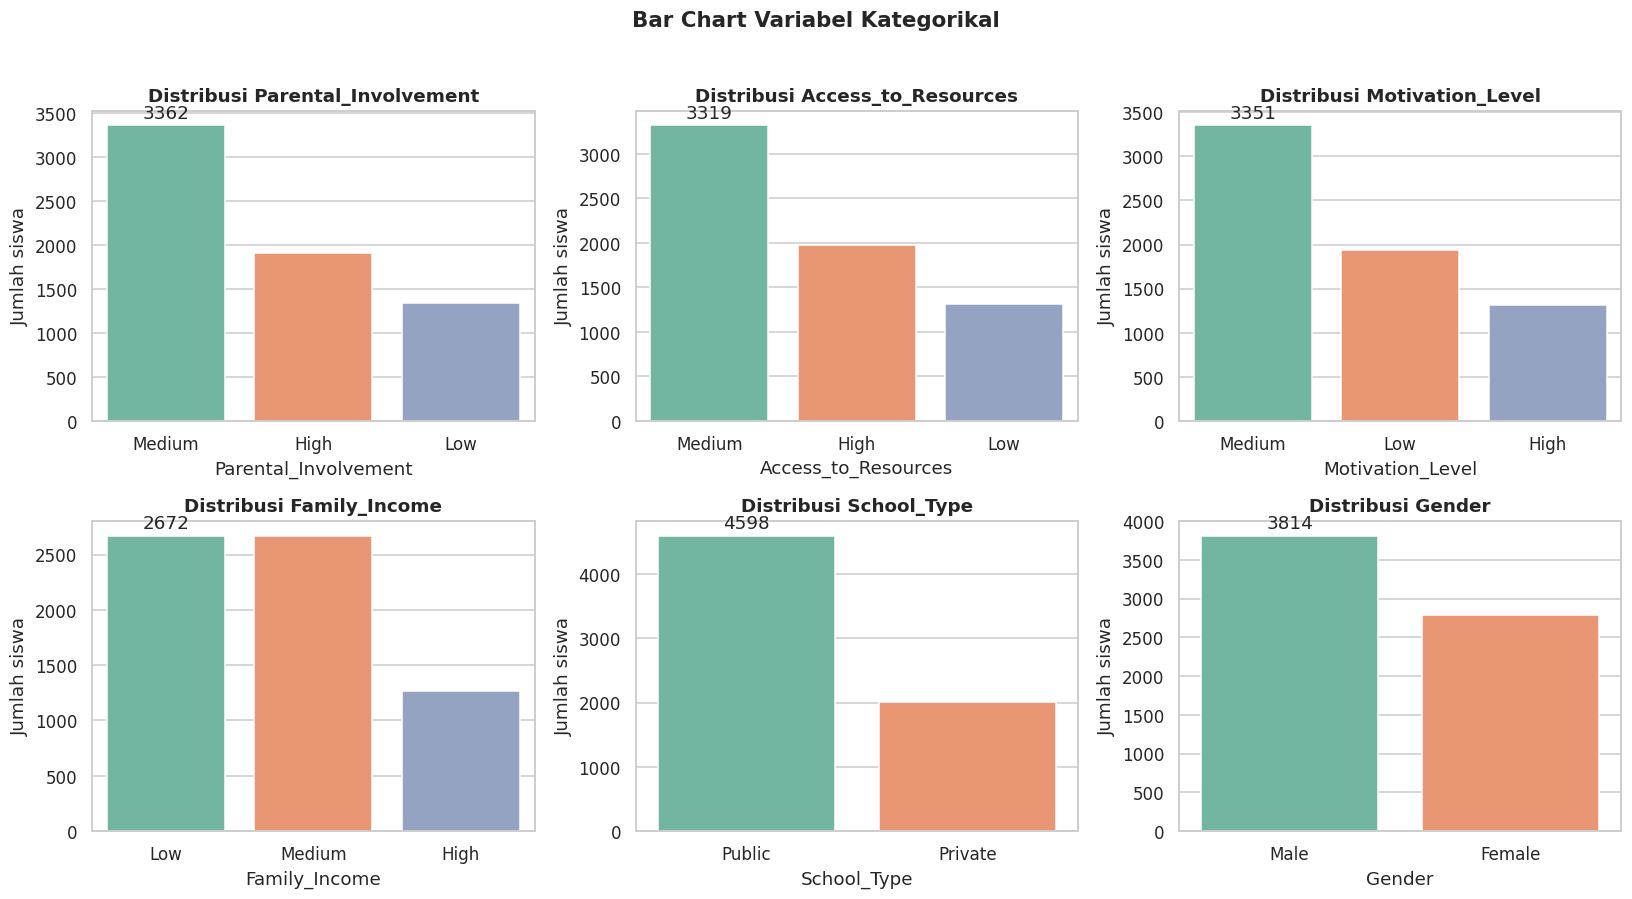

In [17]:
cat_vars = ["Parental_Involvement", "Access_to_Resources", "Motivation_Level",
            "Family_Income", "School_Type", "Gender"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, v in zip(axes.ravel(), cat_vars):
    order = df_clean[v].value_counts().index
    sns.countplot(data=df_clean, x=v, order=order, palette="Set2", ax=ax)
    ax.bar_label(ax.containers[0], padding=2)
    ax.set_title(f"Distribusi {v}")
    ax.set_xlabel(v)
    ax.set_ylabel("Jumlah siswa")
plt.suptitle("Bar Chart Variabel Kategorikal", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Interpretasi.**
- **`Parental_Involvement`, `Access_to_Resources`, `Motivation_Level`**: kategori *Medium* paling banyak, sedangkan *Low* dan *High* lebih sedikit. Pola ini membentuk distribusi yang "menggembung" di tengah.
- **`Family_Income`**: kategori *Low* dan *Medium* hampir sama banyak, sementara *High* paling sedikit.
- **`School_Type`**: siswa sekolah *Public* jauh lebih banyak dibanding *Private* (sekitar dua kali lipat lebih).
- **`Gender`**: jumlah siswa laki-laki lebih banyak daripada perempuan.
- Karena ada kategori yang jumlahnya jauh lebih kecil, perbandingan antar kelompok harus dibaca dengan hati-hati (ukuran sampel kelompok tidak sama).

## 6. Bivariate Visualization

**Tujuan:** melihat hubungan antara beberapa variabel penjelas dengan **variabel fokus `Exam_Score`**.

**Langkah:**
1. **Scatter plot** (dengan garis regresi) untuk 3 pasang variabel numerik: `Hours_Studied`, `Attendance`, dan `Previous_Scores` terhadap `Exam_Score`. Koefisien korelasi Pearson ditampilkan pada judul tiap grafik.
2. **Boxplot berkelompok** untuk 3 variabel kategorikal: `Parental_Involvement`, `Access_to_Resources`, dan `Motivation_Level` terhadap `Exam_Score`.
3. Menghitung rata-rata `Exam_Score` tiap kelompok untuk memperjelas selisihnya.

### 6.1 Numerik vs `Exam_Score` (Scatter Plot)

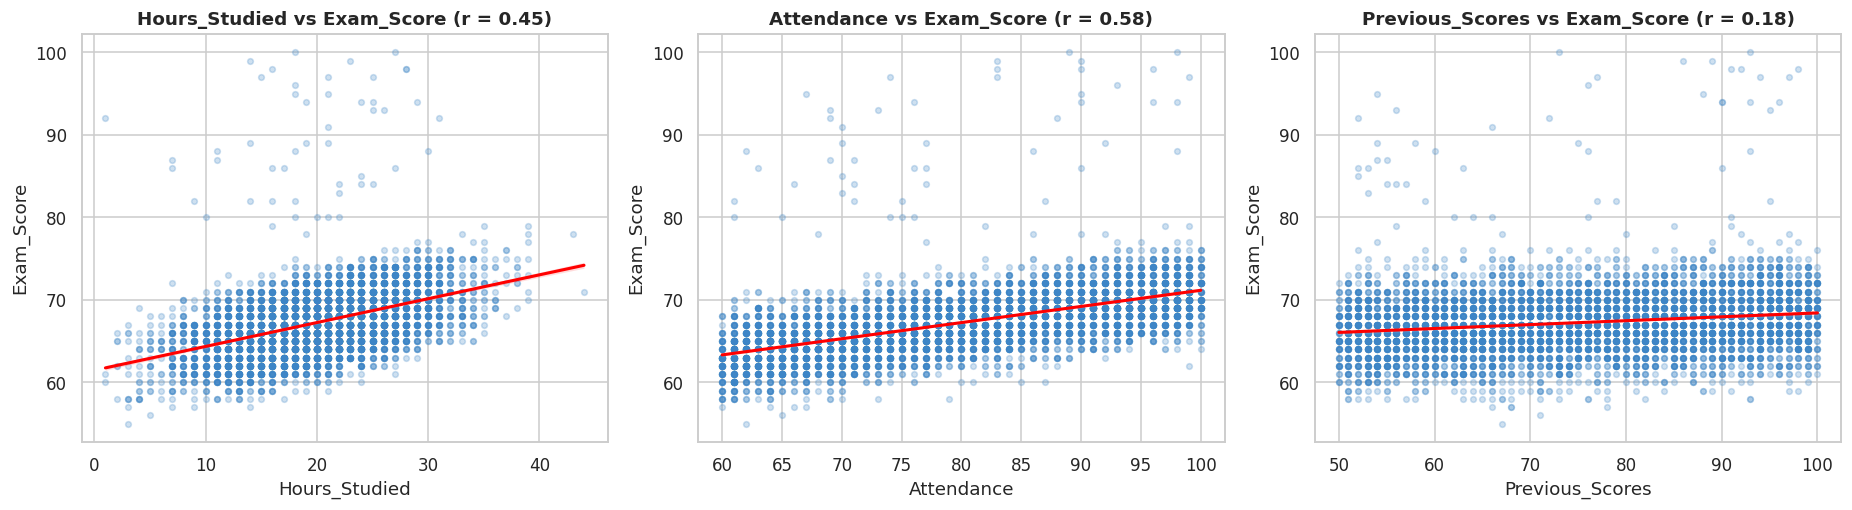

In [18]:
biv_num = ["Hours_Studied", "Attendance", "Previous_Scores"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, v in zip(axes, biv_num):
    r = df_clean[v].corr(df_clean["Exam_Score"])
    sns.regplot(data=df_clean, x=v, y="Exam_Score",
                scatter_kws={"alpha": 0.25, "s": 14, "color": "#3d85c6"},
                line_kws={"color": "red", "lw": 2}, ax=ax)
    ax.set_title(f"{v} vs Exam_Score (r = {r:.2f})")
    ax.set_xlabel(v)
    ax.set_ylabel("Exam_Score")
plt.tight_layout()
plt.show()

In [19]:
# Korelasi Pearson seluruh variabel numerik terhadap Exam_Score
(df_clean[num_cols].corr()["Exam_Score"]
    .drop("Exam_Score").sort_values(ascending=False).to_frame("korelasi_dengan_Exam_Score"))

,korelasi_dengan_Exam_Score
Attendance,0.581
Hours_Studied,0.446
Previous_Scores,0.175
Tutoring_Sessions,0.156
Physical_Activity,0.028
Sleep_Hours,-0.017


**Interpretasi.**
- **`Attendance` vs `Exam_Score`**: hubungan **positif yang paling kuat** di antara ketiganya (r sekitar 0,58). Semakin tinggi kehadiran, semakin tinggi nilai ujian, dan titik-titiknya mengikuti garis tren dengan cukup rapat.
- **`Hours_Studied` vs `Exam_Score`**: hubungan **positif sedang** (r sekitar 0,45). Siswa yang belajar lebih lama cenderung memperoleh nilai lebih tinggi, tetapi sebarannya lebih lebar dibanding kehadiran.
- **`Previous_Scores` vs `Exam_Score`**: hubungan **positif lemah** (r sekitar 0,17). Nilai sebelumnya hanya sedikit memprediksi nilai ujian akhir, dan awan titiknya hampir membulat.
- Tabel korelasi juga menunjukkan bahwa `Sleep_Hours` dan `Physical_Activity` hampir tidak berhubungan dengan `Exam_Score` (r mendekati nol).

### 6.2 Kategorikal vs `Exam_Score` (Boxplot Berkelompok)

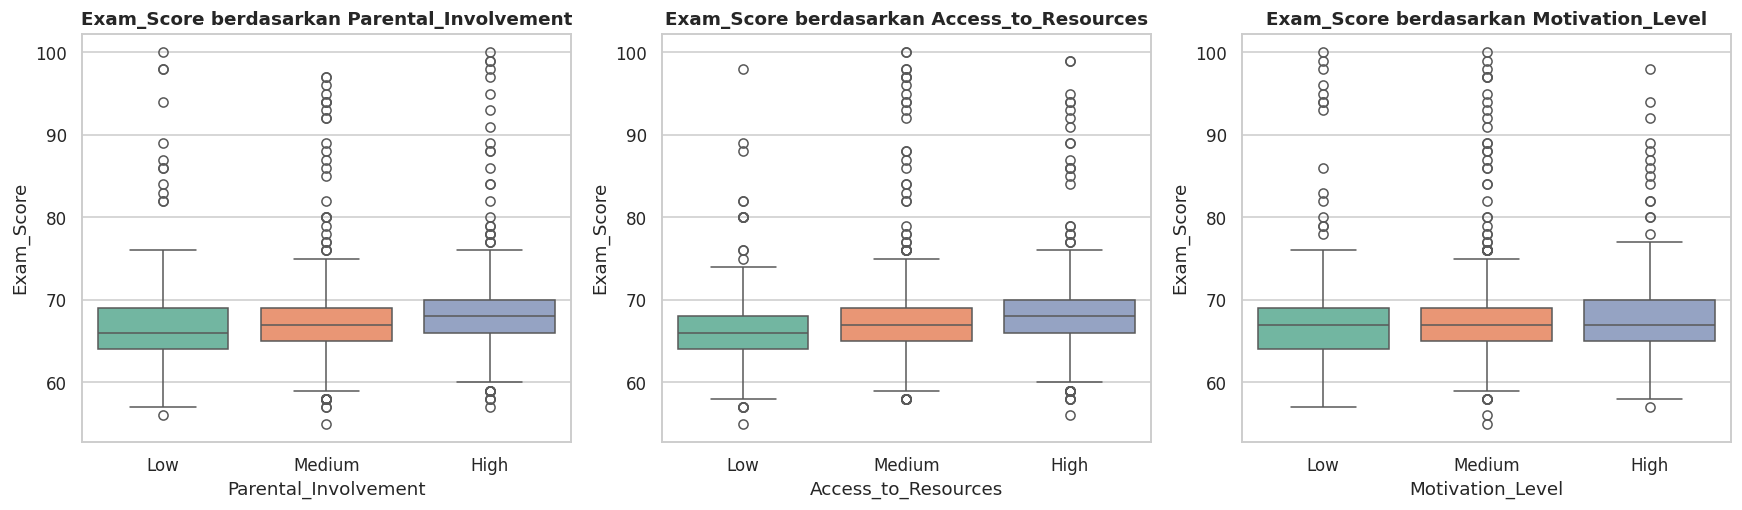

In [20]:
biv_cat = ["Parental_Involvement", "Access_to_Resources", "Motivation_Level"]
order_lmh = ["Low", "Medium", "High"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, v in zip(axes, biv_cat):
    sns.boxplot(data=df_clean, x=v, y="Exam_Score", order=order_lmh, palette="Set2", ax=ax)
    ax.set_title(f"Exam_Score berdasarkan {v}")
    ax.set_xlabel(v)
    ax.set_ylabel("Exam_Score")
plt.tight_layout()
plt.show()

In [21]:
# Rata-rata Exam_Score per kelompok
for v in biv_cat:
    tbl = (df_clean.groupby(v)["Exam_Score"].agg(["count", "mean", "median", "std"])
           .reindex(order_lmh))
    print(f"--- {v} ---")
    display(tbl)

--- Parental_Involvement ---


,count,mean,median,std
Parental_Involvement,,,,
Low,1337,66.358,66.000,3.965
Medium,3362,67.098,67.000,3.728
High,1908,68.093,68.000,3.948


--- Access_to_Resources ---


,count,mean,median,std
Access_to_Resources,,,,
Low,1313,66.203,66.000,3.562
Medium,3319,67.134,67.000,3.867
High,1975,68.092,68.000,3.948


--- Motivation_Level ---


,count,mean,median,std
Motivation_Level,,,,
Low,1937,66.752,67.000,3.954
Medium,3351,67.331,67.000,3.827
High,1319,67.704,67.000,3.877


**Interpretasi.** Ketiga variabel kategorikal menunjukkan pola **positif yang berurutan**: kelompok *High* memiliki median `Exam_Score` tertinggi, diikuti *Medium*, lalu *Low*. Artinya keterlibatan orang tua, akses ke sumber belajar, dan motivasi yang lebih tinggi berkaitan dengan nilai yang lebih baik. Namun, selisih antar kelompok relatif **kecil** (kira-kira 1–2 poin) dan kotak boxplot saling tumpang tindih cukup besar. Jadi pengaruhnya nyata tetapi tidak sebesar `Attendance` dan `Hours_Studied`. Karena ini analisis eksploratif, hubungan tersebut belum dapat disimpulkan sebagai sebab-akibat.

## 7. Multivariate Visualization

**Tujuan:** melihat pola hubungan antar banyak variabel numerik sekaligus.

**Langkah:**
1. **Correlation heatmap** untuk seluruh variabel numerik (korelasi Pearson).
2. **Scatterplot matrix (pair plot)** untuk 4 variabel numerik (`Hours_Studied`, `Attendance`, `Previous_Scores`, `Exam_Score`) dengan pewarnaan (*hue*) berdasarkan `Parental_Involvement`. Agar grafik tetap ringan dan terbaca, saya memakai sampel acak 1.000 baris.

### 7.1 Correlation Heatmap

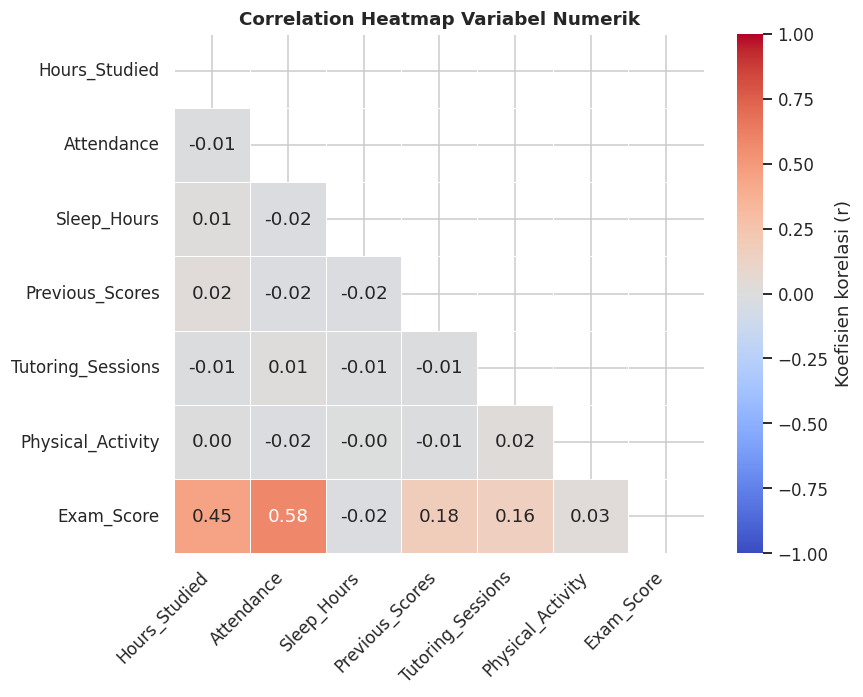

In [22]:
corr = df_clean[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Koefisien korelasi (r)"})
plt.title("Correlation Heatmap Variabel Numerik")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretasi.**
- Baris `Exam_Score` memperlihatkan bahwa `Attendance` (sekitar 0,58) dan `Hours_Studied` (sekitar 0,45) adalah dua variabel dengan korelasi terkuat. `Previous_Scores` dan `Tutoring_Sessions` berkorelasi positif lemah (sekitar 0,16–0,17), sementara `Physical_Activity` dan `Sleep_Hours` hampir nol.
- **Korelasi antar variabel penjelas sangat rendah** (mendekati nol). Artinya masalah multikolinearitas hampir tidak ada, dan tiap variabel membawa informasi yang relatif independen.
- Tidak ada pasangan variabel yang berkorelasi negatif secara berarti.

### 7.2 Scatterplot Matrix (Pair Plot)

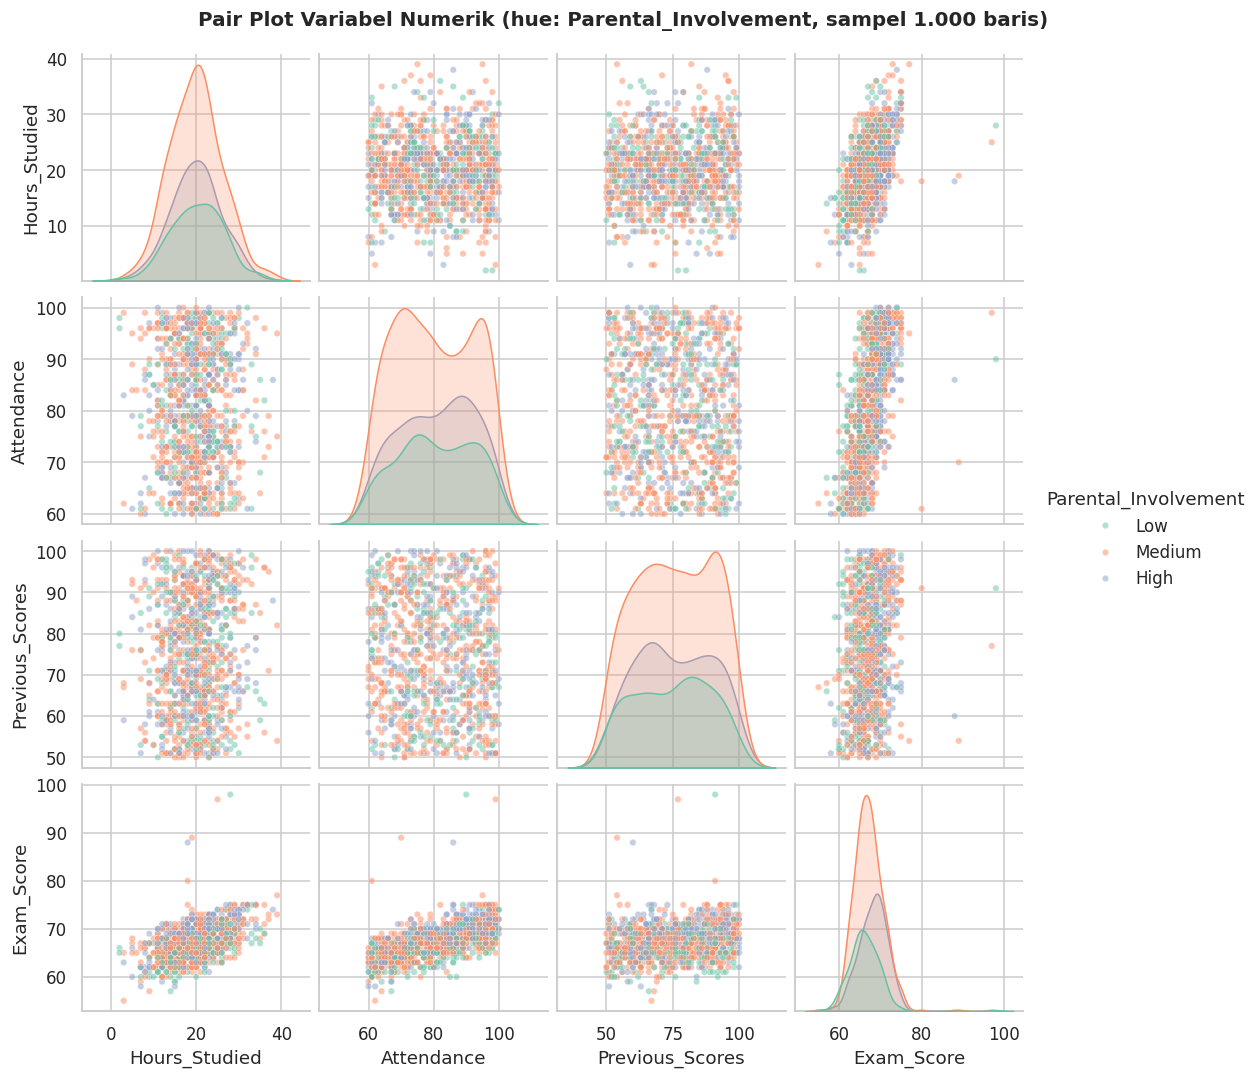

In [23]:
pair_vars = ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]
sample = df_clean.sample(n=min(1000, len(df_clean)), random_state=RANDOM_STATE)

g = sns.pairplot(sample, vars=pair_vars, hue="Parental_Involvement",
                 hue_order=order_lmh, diag_kind="kde", palette="Set2",
                 plot_kws={"alpha": 0.5, "s": 18}, height=2.4)
g.fig.suptitle("Pair Plot Variabel Numerik (hue: Parental_Involvement, sampel 1.000 baris)",
               y=1.02, fontsize=13, fontweight="bold")
plt.show()

**Interpretasi.**
- Pada baris/kolom `Exam_Score`, pola naik tampak jelas terhadap `Attendance` dan `Hours_Studied`, sedangkan terhadap `Previous_Scores` polanya lemah.
- Scatter antar variabel penjelas (misalnya `Hours_Studied` vs `Attendance`) berbentuk awan tanpa pola, sesuai dengan korelasi yang rendah pada heatmap.
- Pewarnaan `Parental_Involvement` menunjukkan titik kelompok *High* cenderung sedikit lebih tinggi pada sumbu `Exam_Score`, tetapi ketiga warna saling tumpang tindih. Jadi faktor ini hanya menggeser nilai sedikit dan tidak memisahkan kelompok dengan tegas. Kurva density pada diagonal juga menunjukkan hal serupa, yaitu puncak kelompok *High* sedikit bergeser ke kanan.

## 8. Dimensionality Reduction (PCA)

**Tujuan:** meringkas variabel-variabel numerik ke sejumlah komponen utama, melihat seberapa besar variansi yang bisa dijelaskan, dan mencari variabel mana yang paling berkontribusi.

**Langkah:**
1. Memilih seluruh variabel numerik (7 variabel) sebagai masukan PCA.
2. **Standardisasi** data dengan `StandardScaler`. Ini wajib karena PCA sensitif terhadap skala (misalnya `Attendance` berskala puluhan, sedangkan `Tutoring_Sessions` berskala satuan).
3. Menjalankan PCA dan melihat ***explained variance ratio*** (individual dan kumulatif) beserta *scree plot*.
4. Melihat ***loading*** tiap variabel terhadap komponen utama untuk mengetahui variabel yang berkontribusi.
5. Memvisualisasikan hasilnya pada **scatter plot 2D** (PC1 vs PC2). **Bonus:** scatter plot 3D dan dendrogram hierarchical clustering.

In [24]:
pca_cols = num_cols
X = df_clean[pca_cols]
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=len(pca_cols), random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)

evr = pd.DataFrame({
    "komponen": [f"PC{i+1}" for i in range(len(pca_cols))],
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "kumulatif": np.cumsum(pca.explained_variance_ratio_),
}).set_index("komponen")
evr["explained_variance_ratio (%)"] = (evr["explained_variance_ratio"] * 100).round(2)
evr["kumulatif (%)"] = (evr["kumulatif"] * 100).round(2)
evr[["explained_variance_ratio (%)", "kumulatif (%)"]]

,explained_variance_ratio (%),kumulatif (%)
komponen,,
PC1,25.220,25.220
PC2,15.000,40.210
PC3,14.600,54.810
PC4,14.520,69.340
PC5,13.870,83.200
PC6,13.580,96.780
PC7,3.220,100.000


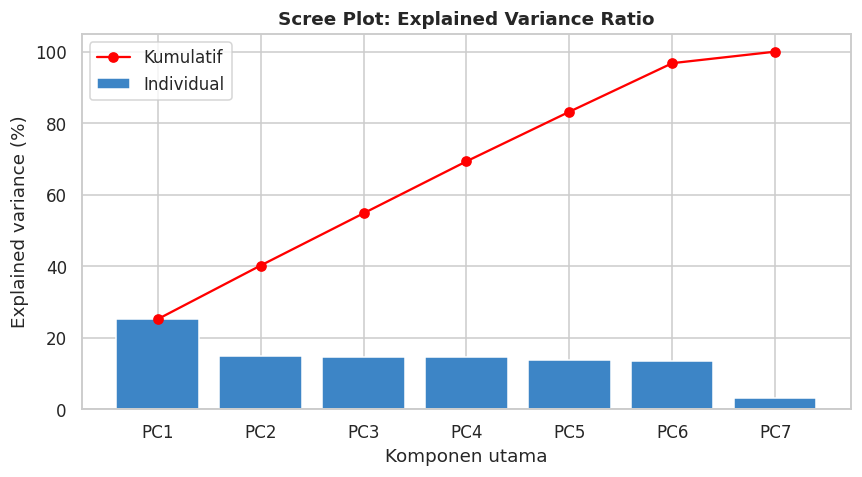

In [25]:
# Scree plot
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(1, len(pca_cols) + 1)
ax.bar(x, pca.explained_variance_ratio_ * 100, color="#3d85c6", label="Individual")
ax.plot(x, np.cumsum(pca.explained_variance_ratio_) * 100, "o-", color="red", label="Kumulatif")
ax.set_xticks(x)
ax.set_xticklabels([f"PC{i}" for i in x])
ax.set_title("Scree Plot: Explained Variance Ratio")
ax.set_xlabel("Komponen utama")
ax.set_ylabel("Explained variance (%)")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretasi explained variance.** PC1 menjelaskan porsi variansi terbesar, tetapi **tidak dominan** (kira-kira seperempat dari total variansi), dan PC2 menyumbang sekitar seperenam. Dua komponen pertama baru mencakup sekitar 40% variansi, sehingga kurva kumulatif naik secara bertahap dan tidak "menekuk" tajam. Hal ini sejalan dengan temuan sebelumnya bahwa variabel-variabel numerik saling berkorelasi rendah. Jika antar variabel hampir independen, informasinya tersebar di banyak komponen, sehingga PCA tidak bisa mengompresi data secara signifikan. Angka persisnya dapat dilihat pada tabel di atas.

,PC1,PC2,PC3
Hours_Studied,0.408,0.542,0.282
Attendance,0.532,-0.445,-0.241
Sleep_Hours,-0.028,0.142,0.391
Previous_Scores,0.160,0.528,-0.278
Tutoring_Sessions,0.145,-0.457,0.320
Physical_Activity,0.014,-0.031,0.728
Exam_Score,0.709,0.003,0.017


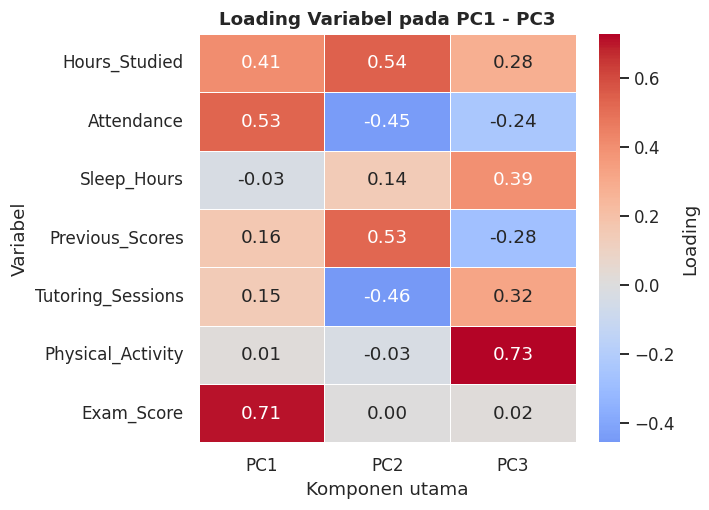

Variabel dengan kontribusi terbesar pada PC1: ['Exam_Score', 'Attendance', 'Hours_Studied']
Variabel dengan kontribusi terbesar pada PC2: ['Hours_Studied', 'Previous_Scores', 'Tutoring_Sessions']


In [26]:
# Loading variabel terhadap komponen utama
loadings = pd.DataFrame(pca.components_[:3].T, index=pca_cols, columns=["PC1", "PC2", "PC3"])
display(loadings.round(3))

plt.figure(figsize=(6.5, 4.8))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5,
            cbar_kws={"label": "Loading"})
plt.title("Loading Variabel pada PC1 - PC3")
plt.ylabel("Variabel")
plt.xlabel("Komponen utama")
plt.tight_layout()
plt.show()

for pc in ["PC1", "PC2"]:
    top = loadings[pc].abs().sort_values(ascending=False).head(3).index.tolist()
    print(f"Variabel dengan kontribusi terbesar pada {pc}: {top}")

**Interpretasi loading.**
- **PC1** didominasi oleh `Exam_Score`, `Attendance`, dan `Hours_Studied` dengan tanda loading yang sama. PC1 dapat dibaca sebagai **"dimensi prestasi dan keseriusan belajar"**: siswa dengan skor PC1 tinggi umumnya rajin hadir, banyak belajar, dan bernilai ujian tinggi.
- **PC2** didominasi variabel lain, terutama `Previous_Scores`, `Tutoring_Sessions`, dan `Physical_Activity`/`Sleep_Hours` (lihat tabel loading). Variabel-variabel ini hampir tidak berkorelasi dengan kelompok variabel di PC1, sehingga ditangkap oleh komponen terpisah.
- Variabel yang berkontribusi besar pada PC1 adalah variabel yang pada analisis bivariat terbukti paling terkait dengan `Exam_Score`. Ini menguatkan temuan sebelumnya.

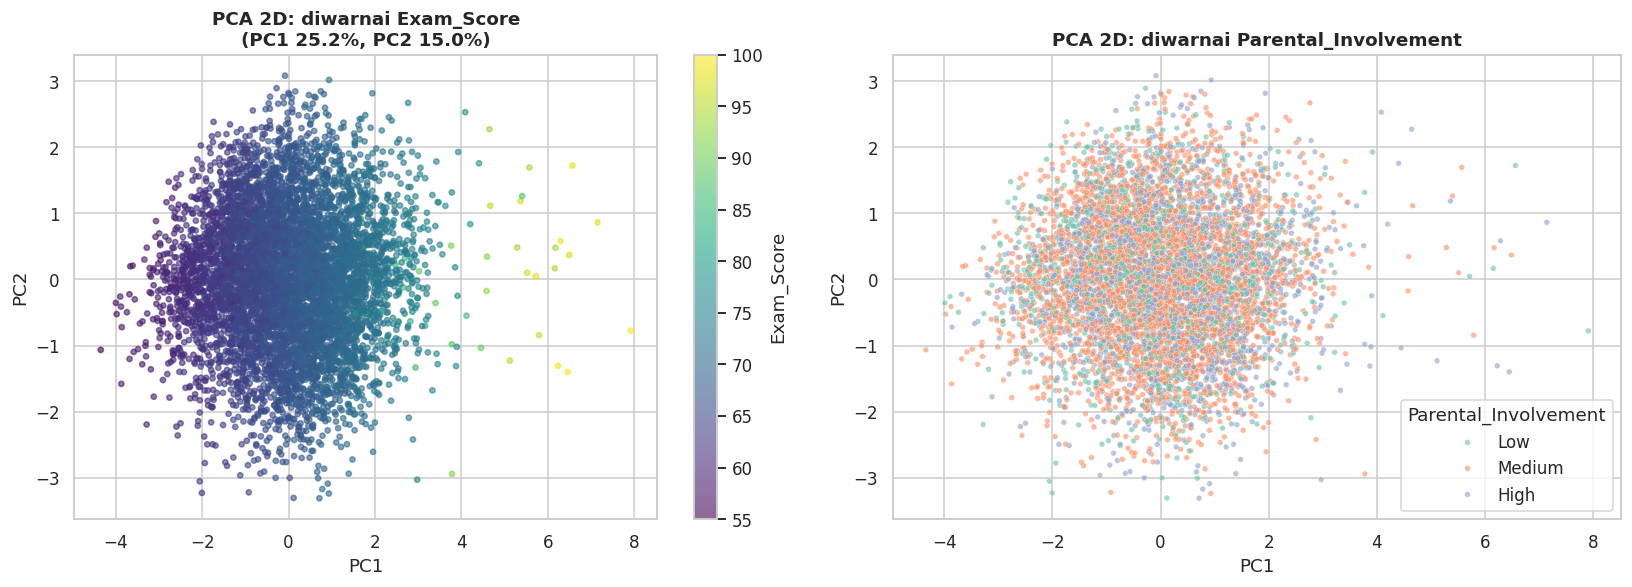

In [27]:
# Scatter plot 2D (PC1 vs PC2)
pc_df = pd.DataFrame(pcs[:, :3], columns=["PC1", "PC2", "PC3"])
pc_df["Exam_Score"] = df_clean["Exam_Score"].values
pc_df["Parental_Involvement"] = df_clean["Parental_Involvement"].values

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sc = axes[0].scatter(pc_df["PC1"], pc_df["PC2"], c=pc_df["Exam_Score"],
                     cmap="viridis", s=12, alpha=0.6)
cb = plt.colorbar(sc, ax=axes[0])
cb.set_label("Exam_Score")
axes[0].set_title(f"PCA 2D: diwarnai Exam_Score\n(PC1 {pca.explained_variance_ratio_[0]*100:.1f}%, PC2 {pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

sns.scatterplot(data=pc_df, x="PC1", y="PC2", hue="Parental_Involvement",
                hue_order=order_lmh, palette="Set2", s=14, alpha=0.6, ax=axes[1])
axes[1].set_title("PCA 2D: diwarnai Parental_Involvement")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend(title="Parental_Involvement")

plt.tight_layout()
plt.show()

**Interpretasi scatter plot 2D.** Pada panel kiri, warna `Exam_Score` berubah **bertahap sepanjang sumbu PC1** (nilai tinggi di satu sisi, nilai rendah di sisi lain), sedangkan sepanjang PC2 perubahannya jauh lebih sedikit. Ini mengonfirmasi bahwa PC1 menangkap dimensi yang berkaitan dengan nilai ujian. Pada panel kanan, kelompok `Parental_Involvement` bercampur dan tidak terpisah jelas. Jadi struktur utama data lebih ditentukan oleh variabel numerik (kehadiran, jam belajar, nilai), bukan oleh keterlibatan orang tua.

### Bonus: Scatter Plot 3D (PC1, PC2, PC3)

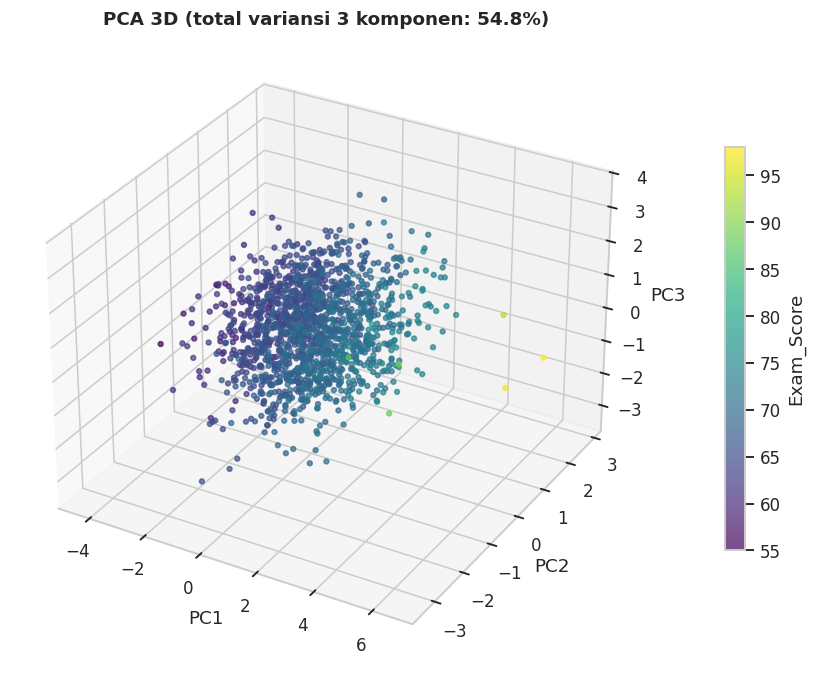

In [28]:
sample3d = pc_df.sample(n=min(1500, len(pc_df)), random_state=RANDOM_STATE)

fig = plt.figure(figsize=(8, 6.5))
ax = fig.add_subplot(111, projection="3d")
p = ax.scatter(sample3d["PC1"], sample3d["PC2"], sample3d["PC3"],
               c=sample3d["Exam_Score"], cmap="viridis", s=10, alpha=0.7)
fig.colorbar(p, ax=ax, shrink=0.6, pad=0.1, label="Exam_Score")
ax.set_title(f"PCA 3D (total variansi 3 komponen: {pca.explained_variance_ratio_[:3].sum()*100:.1f}%)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
plt.tight_layout()
plt.show()

**Interpretasi.** Penambahan PC3 memperlihatkan bahwa sebaran data tetap berbentuk satu gumpalan besar tanpa kelompok yang terpisah. Gradasi warna `Exam_Score` masih paling jelas searah PC1. Tiga komponen pertama baru menjelaskan sekitar separuh variansi, jadi visualisasi 3D hanya memberi tambahan informasi yang terbatas.

### Bonus: Dendrogram Hierarchical Clustering

Untuk melihat struktur pengelompokan data, saya membuat dendrogram dengan metode *Ward* pada data yang sudah distandardisasi. Karena dendrogram berat untuk ribuan baris, saya memakai sampel acak 100 baris.

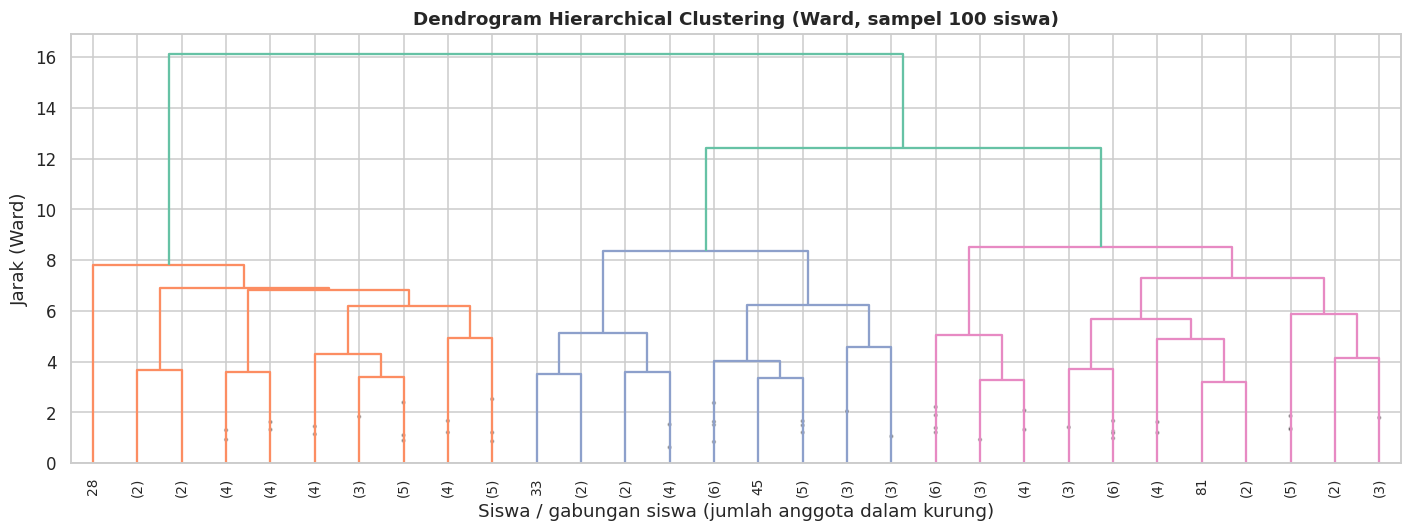

In [29]:
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), size=100, replace=False)
Z = linkage(X_scaled[idx], method="ward")

plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=0.7 * max(Z[:, 2]))
plt.title("Dendrogram Hierarchical Clustering (Ward, sampel 100 siswa)")
plt.xlabel("Siswa / gabungan siswa (jumlah anggota dalam kurung)")
plt.ylabel("Jarak (Ward)")
plt.tight_layout()
plt.show()

**Interpretasi.** Dendrogram menunjukkan penggabungan data berlangsung bertahap, dan lompatan jarak terbesar terjadi pada penggabungan beberapa cabang terakhir. Pemotongan pada ketinggian yang memberi sekitar 2–4 kelompok terlihat paling masuk akal. Tidak tampak satu pemisahan yang sangat tegas, yang konsisten dengan hasil PCA bahwa data berbentuk satu gumpalan tanpa kluster alami yang jelas.

## 9. Insight, Kesimpulan, dan Rekomendasi

In [30]:
# Ringkasan angka kunci untuk mendukung insight
corr_target = df_clean[num_cols].corr()["Exam_Score"].drop("Exam_Score").sort_values(ascending=False)
print("Korelasi variabel numerik dengan Exam_Score:")
print(corr_target.round(3).to_string())

print(f"\nRata-rata Exam_Score : {df_clean['Exam_Score'].mean():.2f} (std {df_clean['Exam_Score'].std():.2f})")
print(f"Variansi dijelaskan PC1+PC2 : {pca.explained_variance_ratio_[:2].sum()*100:.1f}%")

Korelasi variabel numerik dengan Exam_Score:
Attendance           0.581
Hours_Studied        0.446
Previous_Scores      0.175
Tutoring_Sessions    0.156
Physical_Activity    0.028
Sleep_Hours         -0.017

Rata-rata Exam_Score : 67.24 (std 3.89)
Variansi dijelaskan PC1+PC2 : 40.2%


### 9.1 Insight Kunci

1. **Kualitas data tergolong baik.** Tidak ada duplikat dan missing value hanya muncul pada 3 kolom kategorikal dengan proporsi di bawah 2%. Satu-satunya anomali yang jelas adalah `Exam_Score` yang melebihi 100, dan sudah dikoreksi.
2. **Nilai ujian mengumpul di rentang sempit.** `Exam_Score` berdistribusi mirip lonceng dengan rata-rata sekitar 67 dan simpangan baku sekitar 4, dengan sedikit outlier di sisi nilai tinggi. Variasi antar siswa tidak besar, sehingga perbedaan antar kelompok akan selalu tampak kecil.
3. **Kehadiran adalah faktor numerik yang paling berkaitan dengan nilai ujian** (r sekitar 0,58), diikuti jam belajar (r sekitar 0,45). Dua variabel inilah yang paling relevan sebagai fokus intervensi.
4. **Nilai sebelumnya dan jumlah sesi les hanya berkaitan lemah** (r sekitar 0,16–0,17). Nilai masa lalu bukan penentu kuat hasil ujian akhir, dan les tambahan hanya memberi dampak kecil.
5. **Jam tidur dan aktivitas fisik hampir tidak berkaitan dengan nilai ujian** (r mendekati nol) pada data ini.
6. **Faktor lingkungan dan keluarga berpengaruh kecil tetapi konsisten arahnya.** Keterlibatan orang tua, akses sumber belajar, dan motivasi yang lebih tinggi sejalan dengan nilai ujian yang lebih tinggi, tetapi selisihnya hanya sekitar 1–2 poin dan sebarannya tumpang tindih.
7. **Variabel penjelas hampir saling independen, dan PCA tidak banyak mengompresi data.** Korelasi antar variabel penjelas sangat rendah, sehingga dua komponen pertama hanya menjelaskan sekitar 40% variansi. PC1 mewakili "dimensi prestasi dan keseriusan belajar" (`Attendance`, `Hours_Studied`, `Exam_Score`).

### 9.2 Kesimpulan

Dari eksplorasi ini, hasil ujian siswa paling erat kaitannya dengan **kebiasaan belajar yang dapat diubah**, yaitu kehadiran di kelas dan jam belajar, bukan dengan kondisi latar belakang seperti nilai sebelumnya, jam tidur, atau aktivitas fisik. Faktor keluarga dan lingkungan (keterlibatan orang tua, akses sumber belajar, motivasi) memberi dukungan tambahan yang kecil namun searah. Karena analisis ini bersifat eksploratif, seluruh temuan menunjukkan **asosiasi**, bukan hubungan sebab-akibat.

### 9.3 Rekomendasi Tindak Lanjut

**Terkait konteks (kebijakan/pendidikan):**
- Prioritaskan program peningkatan **kehadiran** dan pendampingan **kebiasaan belajar**, karena keduanya paling berkaitan dengan nilai ujian.
- Dorong keterlibatan orang tua dan pemerataan akses sumber belajar sebagai dukungan pendukung.

**Terkait pemodelan lanjutan:**
- **Fitur yang layak dipertahankan:** `Attendance`, `Hours_Studied`, `Previous_Scores`, `Tutoring_Sessions`, serta variabel kategorikal `Parental_Involvement`, `Access_to_Resources`, dan `Motivation_Level`.
- **Fitur yang dapat dipertimbangkan untuk dibuang atau diuji ulang:** `Sleep_Hours` dan `Physical_Activity` karena hampir tidak berkorelasi dengan target.
- PCA **tidak perlu** dipakai untuk reduksi dimensi karena tidak banyak menyederhanakan data. Fitur asli sudah cukup informatif dan lebih mudah diinterpretasi.

**Tantangan data yang perlu ditangani lebih dulu:**
- Variabel kategorikal ordinal (Low/Medium/High) perlu *encoding* yang tepat (ordinal encoding), sedangkan variabel nominal memerlukan one-hot encoding.
- Ketidakseimbangan kelompok (misalnya `School_Type` dan `Gender`) perlu diperhatikan saat evaluasi model, misalnya dengan validasi berstrata.
- Outlier pada `Tutoring_Sessions` dan `Exam_Score` perlu diuji pengaruhnya, misalnya apakah model tetap stabil dengan atau tanpa outlier tersebut.
- Imputasi modus adalah solusi sederhana. Untuk model yang lebih serius, bandingkan dengan metode imputasi lain.
- Hubungan yang ditemukan bersifat korelasional, sehingga kesimpulan sebab-akibat memerlukan desain studi yang berbeda.

## 10. Lembar Deklarasi Penggunaan AI

> Saya, **Faisal Surya Saputra / 103012330152**, menyatakan bahwa saya **menggunakan** alat AI generatif dalam pengerjaan tugas ini. Seluruh interpretasi, insight, dan kesimpulan yang disampaikan merupakan hasil pemahaman saya sendiri.

| No | Nama Tools AI | Bagian yang Dibantu | Bentuk Bantuan / Tujuan Prompt | Tingkat Ketergantungan |
|----|---------------|---------------------|--------------------------------|------------------------|
| 1 | Claude (Anthropic) | Kerangka notebook dan kode (Bagian 2–8) | Membantu menyusun struktur notebook sesuai deskripsi tugas serta menuliskan kode profiling, cleaning, visualisasi, dan PCA | Sedang |
| 2 | Claude (Anthropic) | Narasi markdown (Bagian 0–9) | Membantu menyusun draf narasi langkah kerja dan interpretasi, yang kemudian saya baca, verifikasi terhadap output, dan sesuaikan | Sedang |
| 3 | ChatGPT (untuk peninjauan notebook ini, jika digunakan dalam hasil akhir) | Evaluasi kesesuaian tugas dan perbaikan struktur/kode EDA | Meminta peninjauan notebook terhadap rubrik tugas dan saran perbaikan | Sedang |
| 4 | Google Gemini | Kerangka kode Python & struktur narasi laporan | Membantu menyusun sintaks EDA, visualisasi, dan PCA | Sedang |


**Lampiran screenshot prompting:** dikumpulkan terpisah dalam satu berkas PDF bernama `Screenshot_AI_[NIM]` *(atau: disisipkan pada sel markdown paling akhir notebook. Pilih salah satu cara dan hapus keterangan yang tidak dipakai)*.

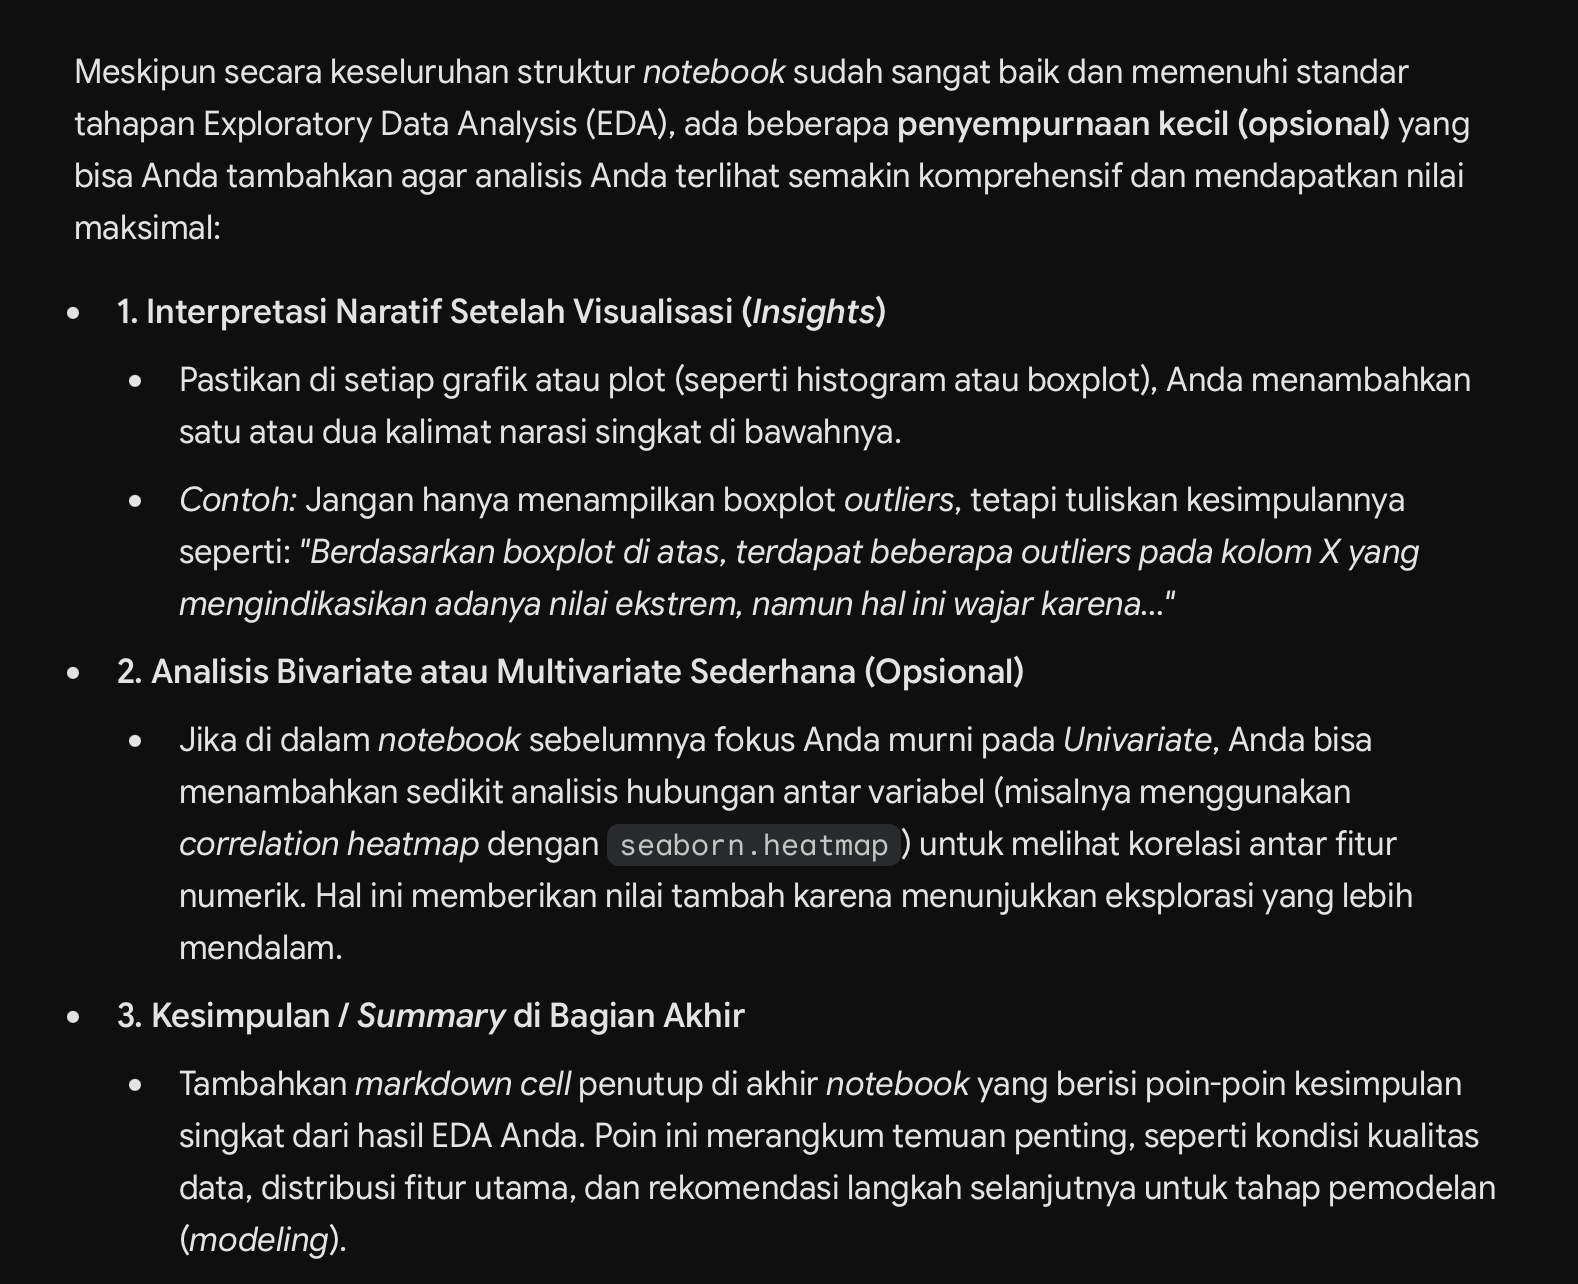

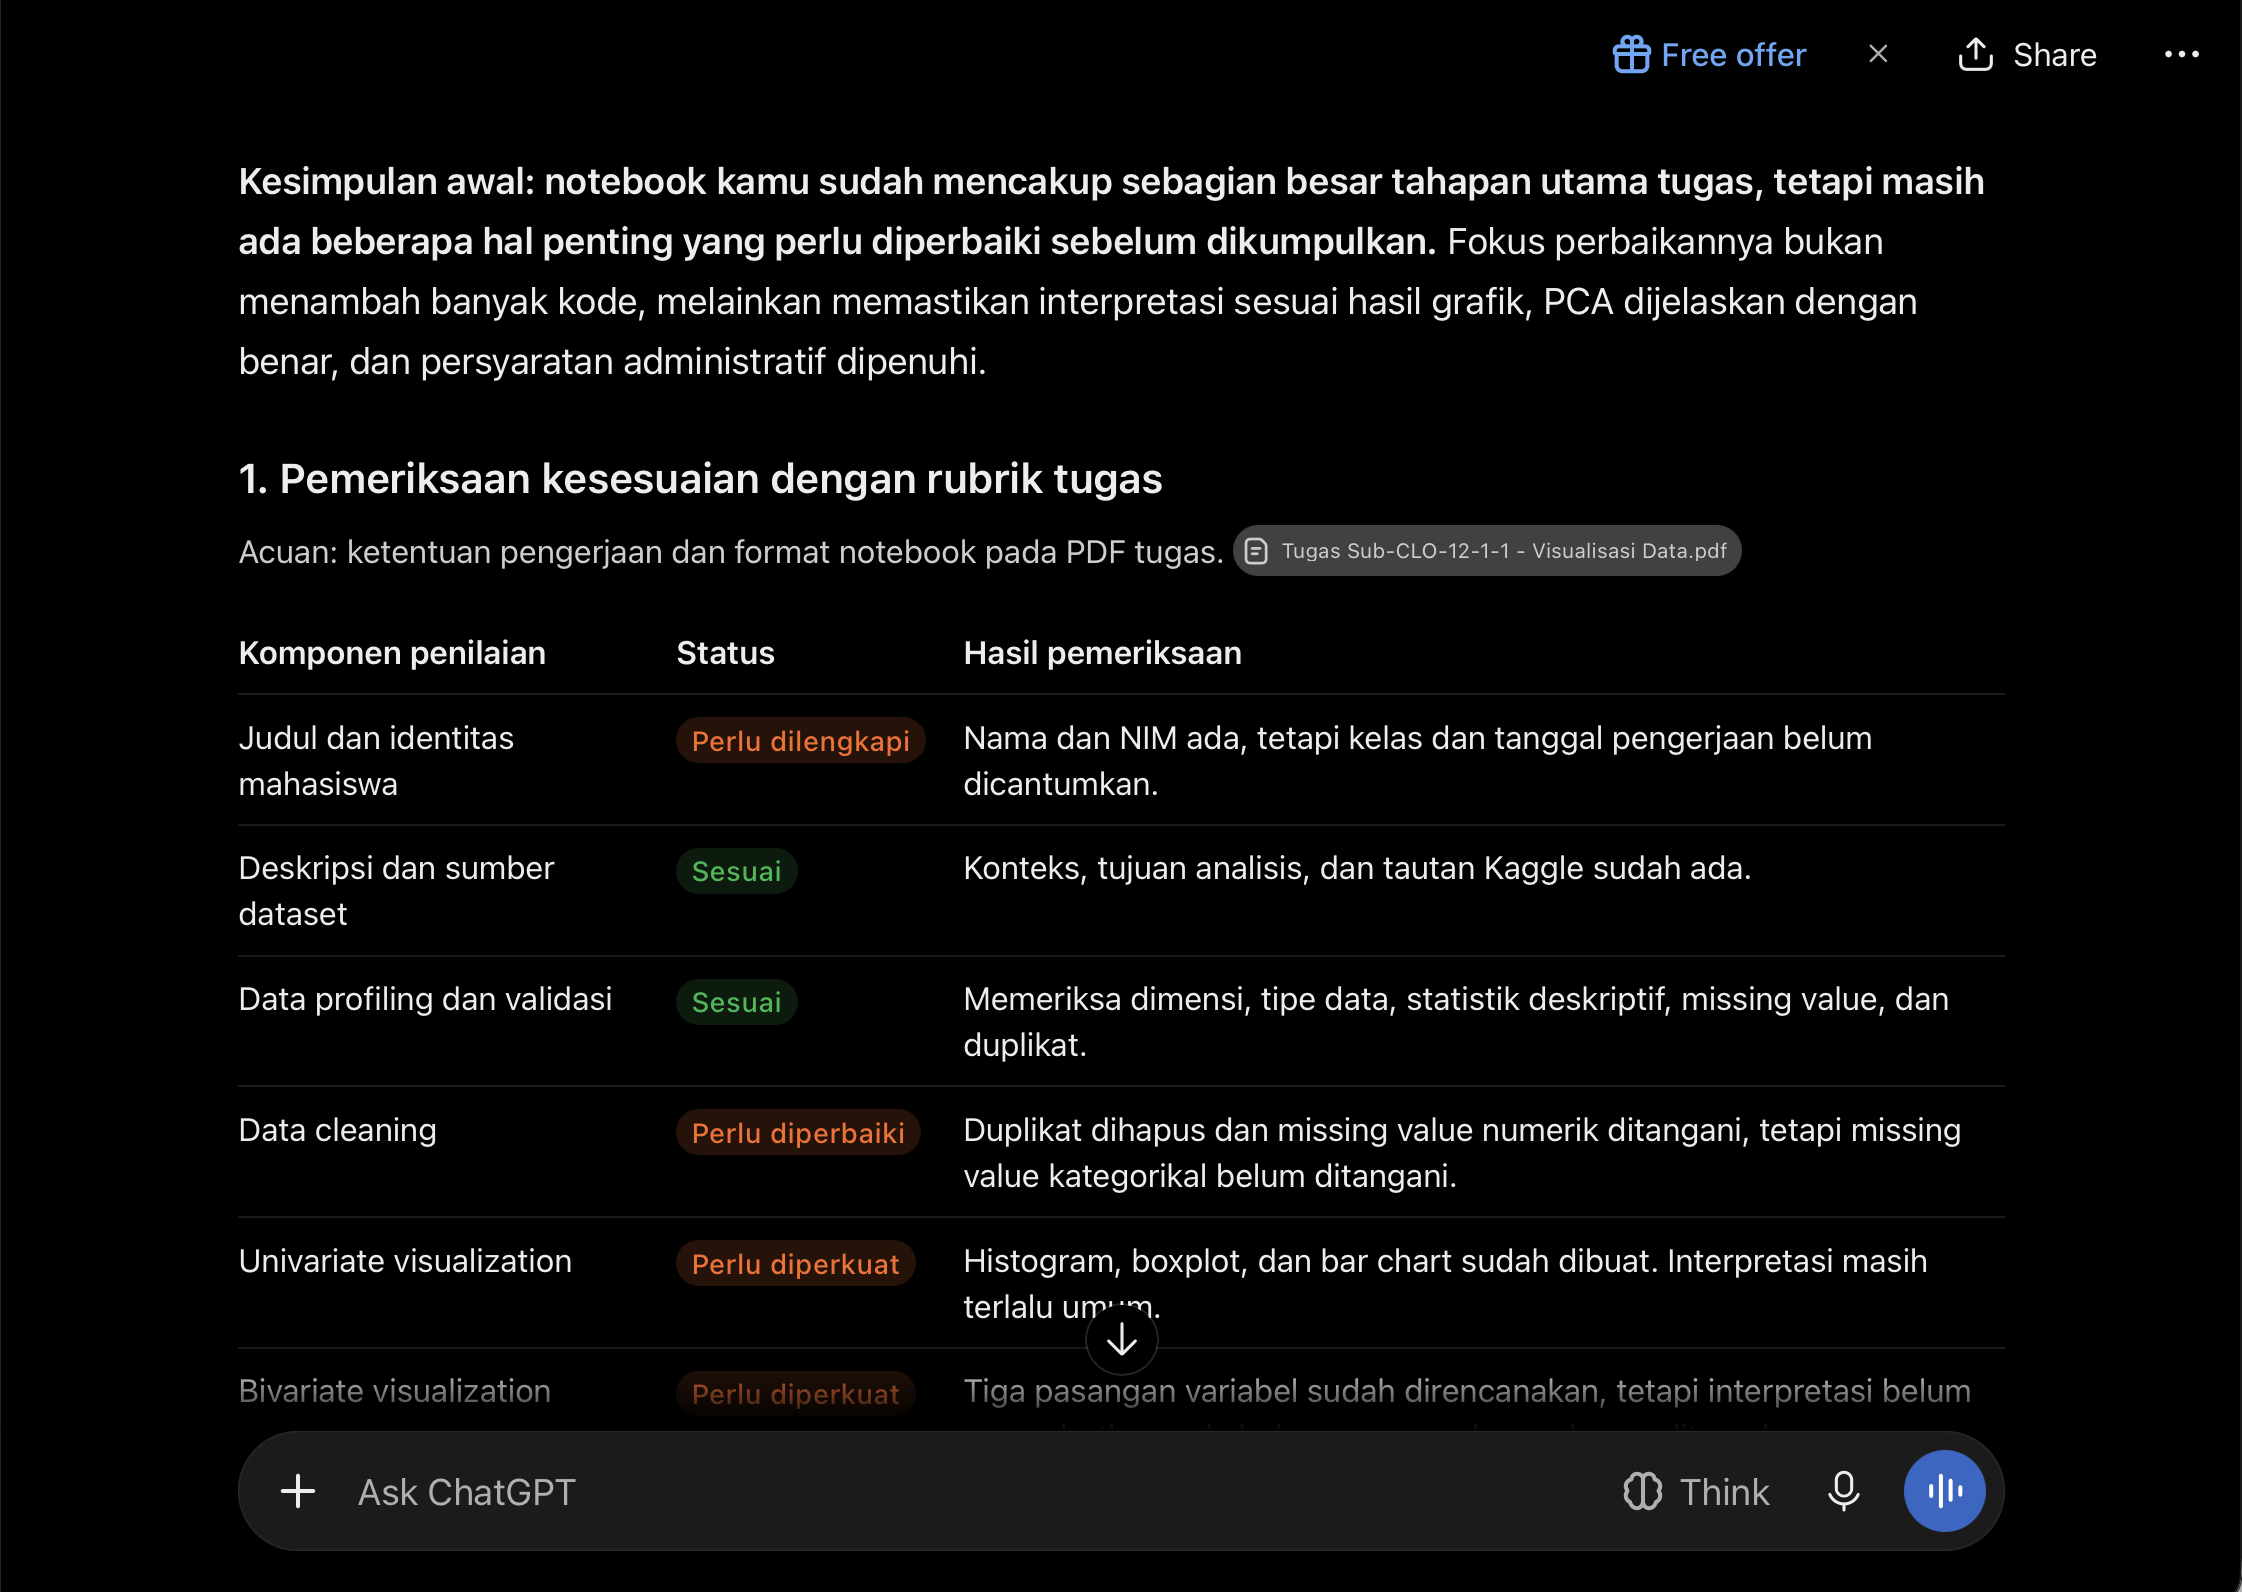

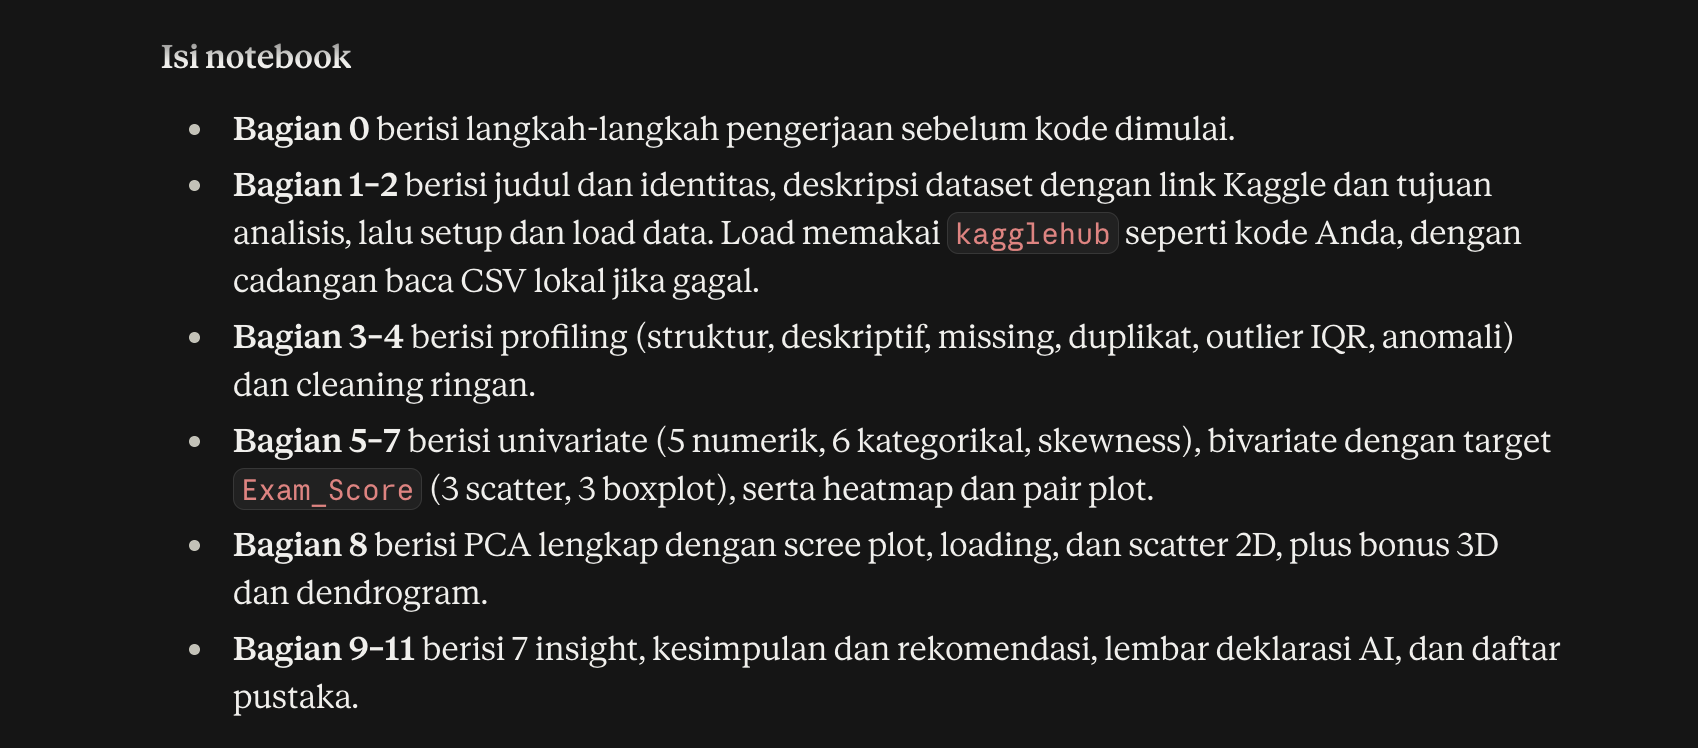

## 11. Daftar Pustaka

1. Nguyen, L. (n.d.). *Student Performance Factors* [Dataset]. Kaggle. https://www.kaggle.com/datasets/lainguyn123/student-performance-factors
2. McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*. (pandas)
3. Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. *Computing in Science & Engineering, 9*(3), 90–95.
4. Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software, 6*(60), 3021.
5. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
6. Materi kuliah Visualisasi Data, Minggu 4: *Exploratory Data Analysis*.